# Lab 14-12 · Multicore, Coherence and Memory Consistency

Companion to [chapter 14-12](../../chapters/14-12-multicore-coherence-consistency.md). `mesi.py` simulates private caches on a snooping bus and checks the coherence invariants after every operation; `litmus.py` enumerates every execution of small litmus tests. Run the cells in order.

In [1]:
import matplotlib.pyplot as plt
import mesi, litmus

## Part 1 · Tracing Example 14-12.1

In [2]:
ops = [(0, 0x100, False), (1, 0x100, False), (0, 0x100, True), (1, 0x100, False), (1, 0x100, True), (0, 0x100, False)]
for proto in ('MSI', 'MESI'):
    s = mesi.System(2, proto)
    print(proto)
    for core, addr, w in ops:
        before = s.bus
        s.access(core, addr, w)
        print(f'  P{core} {"write" if w else "read "}: bus +{s.bus - before}  states', [c.get(addr // 64, 'I') for c in s.state])
    print('  total bus transactions', s.bus, dict(s.stats))

MSI
  P0 read : bus +1  states ['S', 'I']
  P1 read : bus +1  states ['S', 'S']
  P0 write: bus +1  states ['M', 'I']
  P1 read : bus +1  states ['S', 'S']
  P1 write: bus +1  states ['I', 'M']
  P0 read : bus +1  states ['S', 'S']
  total bus transactions 6 {'accesses': 6, 'misses': 4, 'cold_misses': 2, 'BusRd': 4, 'cache_to_cache': 3, 'BusUpgr': 2, 'invalidations': 2, 'coherence_misses': 2, 'flush': 2}
MESI
  P0 read : bus +1  states ['E', 'I']
  P1 read : bus +1  states ['S', 'S']
  P0 write: bus +1  states ['M', 'I']
  P1 read : bus +1  states ['S', 'S']
  P1 write: bus +1  states ['I', 'M']
  P0 read : bus +1  states ['S', 'S']
  total bus transactions 6 {'accesses': 6, 'misses': 4, 'cold_misses': 2, 'BusRd': 4, 'cache_to_cache': 3, 'BusUpgr': 2, 'invalidations': 2, 'coherence_misses': 2, 'flush': 2}


## Part 2 · False sharing

packed [3001, 7001, 15001]  padded [2, 4, 8]


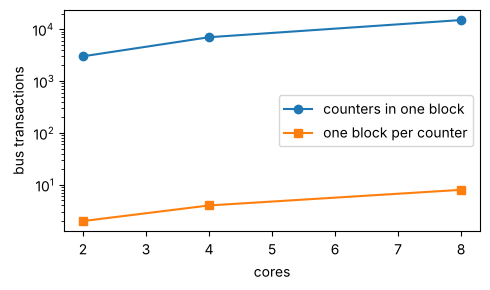

In [3]:
cores = [2, 4, 8]
packed = [mesi.System(n).run(mesi.counters(n, 1000, 4)).bus for n in cores]
padded = [mesi.System(n).run(mesi.counters(n, 1000, 64)).bus for n in cores]
print('packed', packed, ' padded', padded)
plt.figure(figsize=(5, 3))
plt.plot(cores, packed, marker='o', label='counters in one block')
plt.plot(cores, padded, marker='s', label='one block per counter')
plt.yscale('log'); plt.xlabel('cores'); plt.ylabel('bus transactions'); plt.legend(); plt.tight_layout(); plt.show()

## Part 3 · Spin locks

In [4]:
for n in range(2, 9):
    tas, ttas = (mesi.System(n).run(mesi.spin_lock(n, 100, k)).bus for k in ('tas', 'ttas'))
    print(f'{n} cores: test-and-set {tas:4d}, test-and-test-and-set {ttas:3d}')

2 cores: test-and-set    4, test-and-test-and-set   5
3 cores: test-and-set  204, test-and-test-and-set   8
4 cores: test-and-set  305, test-and-test-and-set  11
5 cores: test-and-set  406, test-and-test-and-set  14
6 cores: test-and-set  507, test-and-test-and-set  17
7 cores: test-and-set  608, test-and-test-and-set  20
8 cores: test-and-set  709, test-and-test-and-set  23


## Part 4 · Litmus tests

**Predict first:** does TSO allow MP's outcome (r1, r2) = (1, 0)?

In [5]:
tests = {'SB': litmus.SB, 'SB + fences': litmus.SB_FENCED, 'MP': litmus.MP, 'MP + fence': litmus.MP_FENCED}
for name, t in tests.items():
    for model in ('SC', 'TSO', 'PSO'):
        print(f'{name:12s} {model:4s}', sorted(litmus.outcomes(t, model)))

SB           SC   [(0, 1), (1, 0), (1, 1)]
SB           TSO  [(0, 0), (0, 1), (1, 0), (1, 1)]
SB           PSO  [(0, 0), (0, 1), (1, 0), (1, 1)]
SB + fences  SC   [(0, 1), (1, 0), (1, 1)]
SB + fences  TSO  [(0, 1), (1, 0), (1, 1)]
SB + fences  PSO  [(0, 1), (1, 0), (1, 1)]
MP           SC   [(0, 0), (0, 42), (1, 42)]
MP           TSO  [(0, 0), (0, 42), (1, 42)]
MP           PSO  [(0, 0), (0, 42), (1, 0), (1, 42)]
MP + fence   SC   [(0, 0), (0, 42), (1, 42)]
MP + fence   TSO  [(0, 0), (0, 42), (1, 42)]
MP + fence   PSO  [(0, 0), (0, 42), (1, 42)]
